# Regenerate the RS-BDNet qualitative overview with larger legends

This notebook uses the existing scientifically generated overview image. It removes the original small bottom legends and recreates them with larger fonts. It does **not** change the images, predictions, ground truth, or error maps, and it does not require a GPU.

In [37]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Change this path if your downloaded image has a different filename.
SOURCE_IMAGE = Path.home() / 'Downloads' / 'qualitative_overview_six_datasets (1).png'

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'transformer').is_dir():
    raise RuntimeError('Open this notebook from the DisasterAdaptiveNet workspace.')

OUTPUT_DIR = PROJECT_ROOT / 'output' / 'RSBDNet_qualitative_results_large_fonts'
OUTPUT_STEM = OUTPUT_DIR / 'qualitative_overview_six_datasets_large_fonts'

# The original legends occupy the bottom of the PNG. Increase this value
# slightly if valid content is removed; decrease it if old legends remain.
CONTENT_BOTTOM_FRACTION = 0.925

LEGEND_FONT_SIZE = 17
LEGEND_TITLE_SIZE = 18

if not SOURCE_IMAGE.is_file():
    raise FileNotFoundError(
        f'Image not found: {SOURCE_IMAGE}\n'
        'Update SOURCE_IMAGE above so it points to your generated PNG.'
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Source: {SOURCE_IMAGE}')
print(f'Output directory: {OUTPUT_DIR}')

Source: /Users/asmaemouradi/Downloads/qualitative_overview_six_datasets (1).png
Output directory: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_qualitative_results_large_fonts


Original size: 5570 x 6068 pixels
Content retained through row: 5612


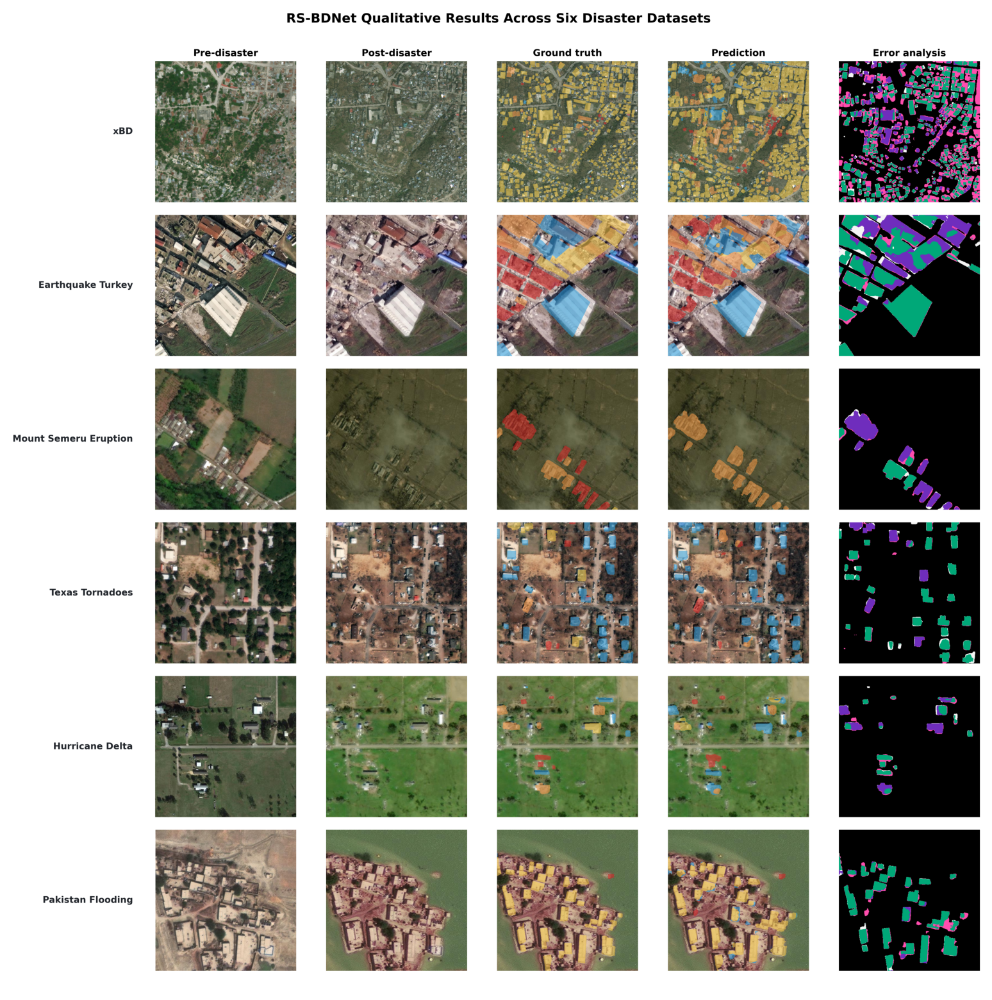

In [38]:
image = plt.imread(SOURCE_IMAGE)
height, width = image.shape[:2]
content_bottom = int(height * CONTENT_BOTTOM_FRACTION)
content = image[:content_bottom, :]

print(f'Original size: {width} x {height} pixels')
print(f'Content retained through row: {content_bottom}')

plt.figure(figsize=(20, 20))
plt.imshow(content)
plt.axis('off')
# plt.title('Preview after removing the original small legends', fontsize=16)
plt.show()

If the old legends are still visible in the preview, reduce `CONTENT_BOTTOM_FRACTION`, for example from `0.925` to `0.915`, and rerun the previous cell.

Wrote: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_qualitative_results_large_fonts/qualitative_overview_six_datasets_large_fonts.png
Wrote: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_qualitative_results_large_fonts/qualitative_overview_six_datasets_large_fonts.pdf
Wrote: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_qualitative_results_large_fonts/qualitative_overview_six_datasets_large_fonts.svg


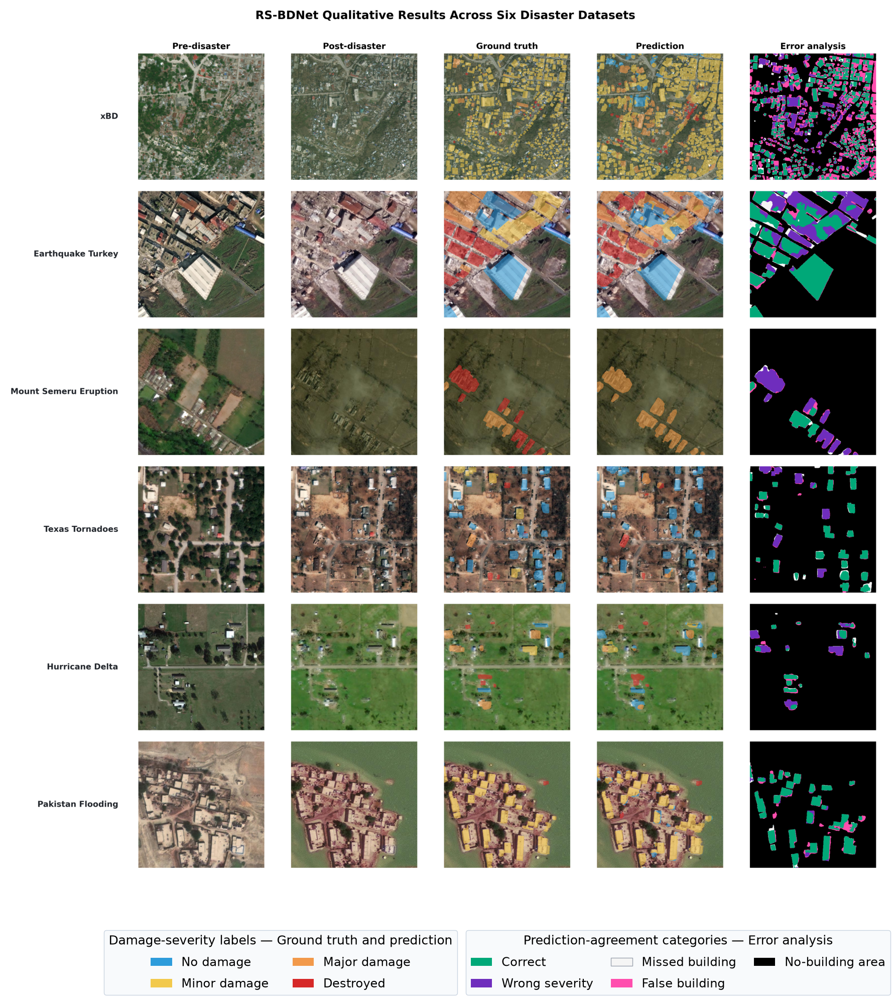

In [39]:
damage_handles = [
    Patch(facecolor='#2D9CDB', label='No damage'),
    Patch(facecolor='#F2C94C', label='Minor damage'),
    Patch(facecolor='#F2994A', label='Major damage'),
    Patch(facecolor='#D62828', label='Destroyed'),
]

error_handles = [
    Patch(facecolor='#00A878', label='Correct'),
    Patch(facecolor='#6F2DBD', label='Wrong severity'),
    Patch(facecolor='#F5F5F5', edgecolor='#9CA3AF', label='Missed building'),
    Patch(facecolor='#FF4EAE', label='False building'),
    Patch(facecolor='black', label='No-building area'),
]

# Preserve the source image's width-to-height ratio and reserve extra
# vertical space for the new, larger legends.
content_ratio = content.shape[0] / content.shape[1]
figure_width = 18
figure_height = figure_width * content_ratio + 2.6
fig = plt.figure(figsize=(figure_width, figure_height), facecolor='white')

image_axis = fig.add_axes([0.015, 0.13, 0.97, 0.855])
image_axis.imshow(content)
image_axis.axis('off')

severity_legend = fig.legend(
    handles=damage_handles,
    title='Damage-severity labels — Ground truth and prediction',
    loc='lower center',
    bbox_to_anchor=(0.32, 0.025),
    ncol=2,
    frameon=True,
    fancybox=True,
    edgecolor='#CBD5E1',
    fontsize=LEGEND_FONT_SIZE,
    title_fontsize=LEGEND_TITLE_SIZE,
    handlelength=1.8,
    columnspacing=2.0,
    labelspacing=0.8,
)
severity_legend.get_frame().set_facecolor('#F8FAFC')
severity_legend.get_frame().set_alpha(1.0)

agreement_legend = fig.legend(
    handles=error_handles,
    title='Prediction-agreement categories — Error analysis',
    loc='lower center',
    bbox_to_anchor=(0.76, 0.025),
    ncol=3,
    frameon=True,
    fancybox=True,
    edgecolor='#CBD5E1',
    fontsize=LEGEND_FONT_SIZE,
    title_fontsize=LEGEND_TITLE_SIZE,
    handlelength=1.8,
    columnspacing=1.5,
    labelspacing=0.8,
)
agreement_legend.get_frame().set_facecolor('#F8FAFC')
agreement_legend.get_frame().set_alpha(1.0)

for suffix, options in [
    ('.png', {'dpi': 350}),
    ('.pdf', {}),
    ('.svg', {}),
]:
    output_path = OUTPUT_STEM.with_suffix(suffix)
    fig.savefig(output_path, bbox_inches='tight', facecolor='white', **options)
    print(f'Wrote: {output_path}')

plt.show()

## Rebuild the complete grid with larger headings and dataset names

The next cell crops the 30 scientific image panels from the original figure and redraws every textual element. The normalized crop coordinates correspond to the overview generated by the RS-BDNet plotting script. If a crop looks slightly displaced, adjust the corresponding value in `COLUMN_RANGES` or `ROW_RANGES`.

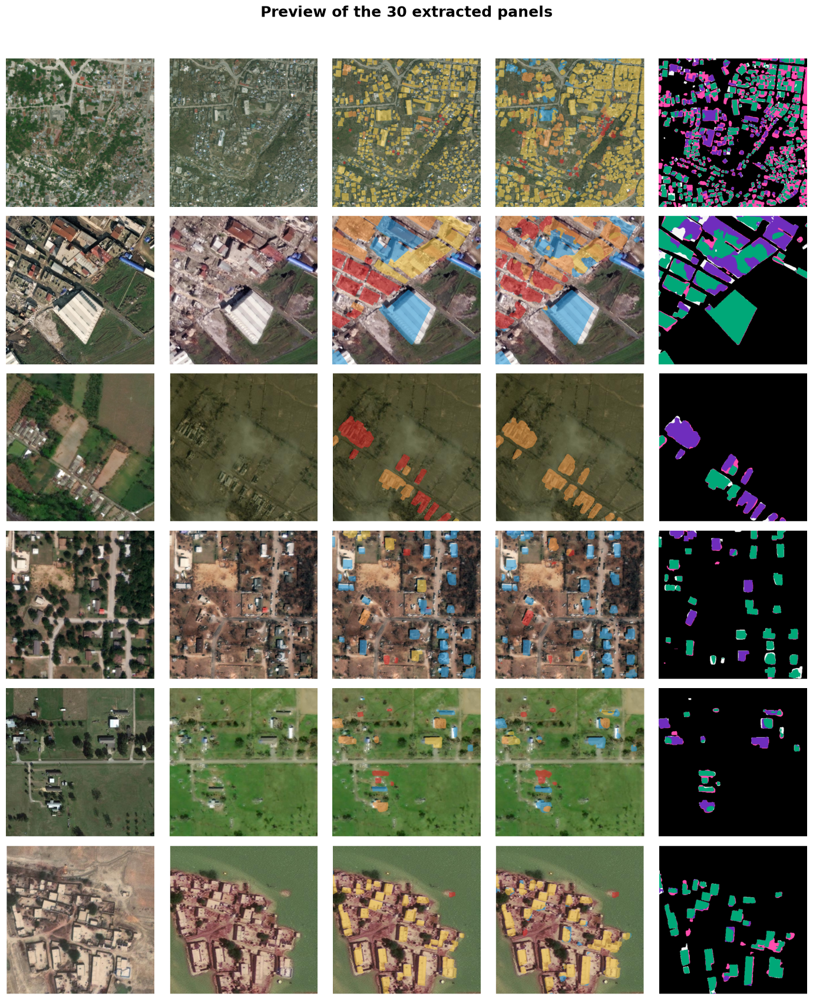

In [40]:
import numpy as np

DATASET_NAMES = [
    'xBD',
    'Earthquake Turkey',
    'Mount Semeru Eruption',
    'Texas Tornadoes',
    'Hurricane Delta',
    'Pakistan Flooding',
]
COLUMN_NAMES = [
    'Pre-disaster',
    'Post-disaster',
    'Ground truth',
    'Prediction',
    'Error analysis',
]

# Coordinates are fractions of the original image width and height.
# Each pair gives the beginning and end of one image panel.
COLUMN_RANGES = [
    (0.152, 0.296),
    (0.326, 0.470),
    (0.501, 0.645),
    (0.675, 0.820),
    (0.850, 0.994),
]
ROW_RANGES = [
    (0.051, 0.183),
    (0.195, 0.327),
    (0.339, 0.472),
    (0.484, 0.616),
    (0.628, 0.760),
    (0.771, 0.904),
]

def crop_fraction(source, x_range, y_range):
    source_height, source_width = source.shape[:2]
    x0, x1 = [int(value * source_width) for value in x_range]
    y0, y1 = [int(value * source_height) for value in y_range]
    return source[y0:y1, x0:x1]

panels = [
    [crop_fraction(image, x_range, y_range) for x_range in COLUMN_RANGES]
    for y_range in ROW_RANGES
]

# Preview the detected panels before building the final figure.
preview, preview_axes = plt.subplots(6, 5, figsize=(14, 17))
for row in range(6):
    for column in range(5):
        preview_axes[row, column].imshow(panels[row][column])
        preview_axes[row, column].axis('off')
preview.suptitle(
    'Preview of the 30 extracted panels',
    fontsize=18, weight='bold', y=0.995,
)
preview.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()

Wrote: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_qualitative_results_large_fonts/qualitative_overview_six_datasets_large_fonts.png
Wrote: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_qualitative_results_large_fonts/qualitative_overview_six_datasets_large_fonts.pdf
Wrote: /Users/asmaemouradi/Documents/GitHub/DisasterAdaptiveNet/output/RSBDNet_qualitative_results_large_fonts/qualitative_overview_six_datasets_large_fonts.svg


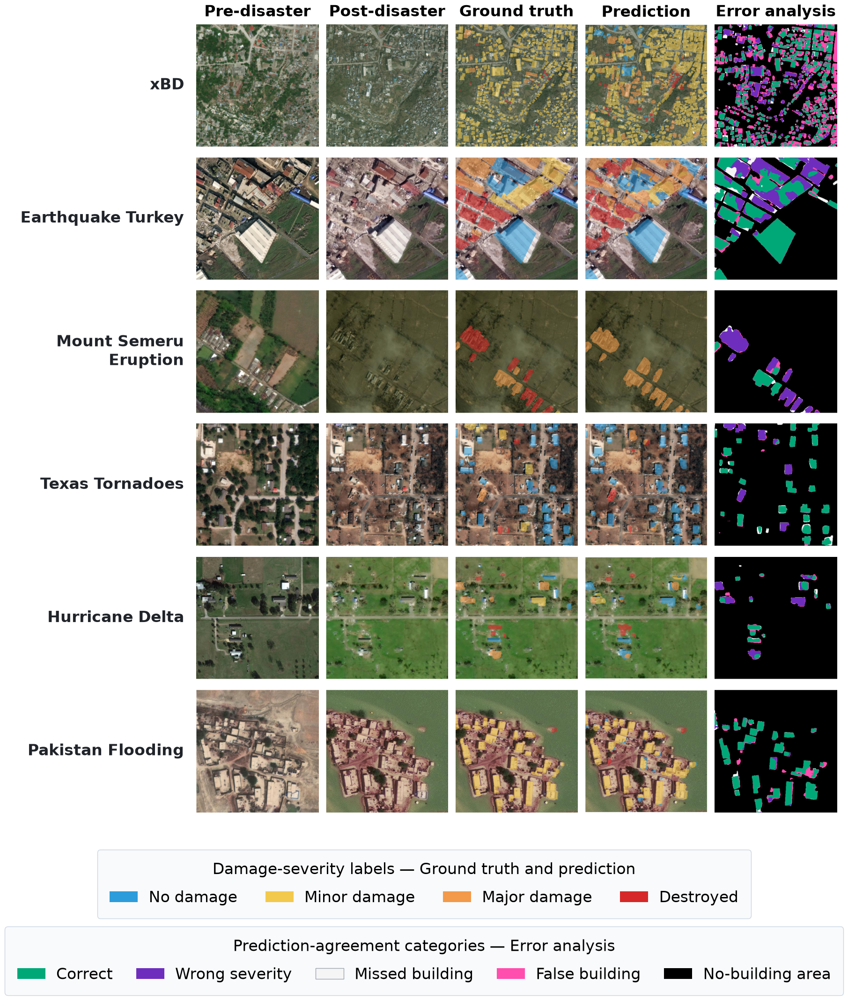

In [43]:
TITLE_FONT_SIZE = 24
COLUMN_FONT_SIZE = 24
DATASET_FONT_SIZE = 24
LEGEND_FONT_SIZE = 24
LEGEND_TITLE_SIZE = 24

fig = plt.figure(figsize=(18, 22.5), facecolor='white')
grid = fig.add_gridspec(
    6, 6,
    width_ratios=(1.35, 1, 1, 1, 1, 1),
    left=0.025, right=0.99, top=0.955, bottom=0.205,
    wspace=0.055, hspace=0.070,
)

for row, dataset_name in enumerate(DATASET_NAMES):
    label_axis = fig.add_subplot(grid[row, 0])
    label_axis.axis('off')
    label_axis.text(
        0.97, 0.5, dataset_name,
        ha='right', va='center', wrap=True,
        fontsize=DATASET_FONT_SIZE, weight='bold', color='#20242A',
    )

    for column, column_name in enumerate(COLUMN_NAMES):
        axis = fig.add_subplot(grid[row, column + 1])
        axis.imshow(panels[row][column])
        axis.axis('off')
        if row == 0:
            axis.set_title(
                column_name, fontsize=COLUMN_FONT_SIZE,
                weight='bold', pad=12,
            )

# fig.suptitle(
#     'RS-BDNet Qualitative Results Across Six Disaster Datasets',
#     fontsize=TITLE_FONT_SIZE, weight='bold', y=0.975,
# )

severity_legend = fig.legend(
    handles=damage_handles,
    title='Damage-severity labels — Ground truth and prediction',
    loc='lower center', bbox_to_anchor=(0.50, 0.098),
    ncol=4, frameon=True, fancybox=True, edgecolor='#CBD5E1',
    fontsize=LEGEND_FONT_SIZE, title_fontsize=LEGEND_TITLE_SIZE,
    handlelength=1.8, handletextpad=0.7, columnspacing=1.8,
    labelspacing=0.8, borderpad=0.8,
)
severity_legend.get_frame().set_facecolor('#F8FAFC')
severity_legend.get_frame().set_alpha(1.0)

agreement_legend = fig.legend(
    handles=error_handles,
    title='Prediction-agreement categories — Error analysis',
    loc='lower center', bbox_to_anchor=(0.50, 0.025),
    ncol=5, frameon=True, fancybox=True, edgecolor='#CBD5E1',
    fontsize=LEGEND_FONT_SIZE, title_fontsize=LEGEND_TITLE_SIZE,
    handlelength=1.8, handletextpad=0.7, columnspacing=1.5,
    labelspacing=0.8, borderpad=0.8,
)
agreement_legend.get_frame().set_facecolor('#F8FAFC')
agreement_legend.get_frame().set_alpha(1.0)

for suffix, options in [('.png', {'dpi': 350}), ('.pdf', {}), ('.svg', {})]:
    output_path = OUTPUT_STEM.with_suffix(suffix)
    fig.savefig(output_path, bbox_inches='tight', facecolor='white', **options)
    print(f'Wrote: {output_path}')

plt.show()